In [591]:
# 데이터 가져오기

# 데이터 전처리

# 데이터 분리

# PolynomialFeatures 다항추가
# degree 추가
# 정규화작업

#### # 데이터 학습
# 규제 적용후 데이터 학습
# alpha값 변경후 데이터 학습 확인

# 데이터 예측
# 정확도

In [592]:
#필요한 도구 가져오기
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [593]:
df= pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head()

,hour,absent,place,score
0,0.5,3,Home,10
1,1.2,4,Library,8
2,1.8,2,Cafe,14
3,2.4,0,Cafe,26
4,2.6,2,Home,22


In [594]:
df['place'].value_counts()

place
Library    7
Cafe       7
Home       6
Name: count, dtype: int64

In [595]:
df[['hour','absent']]
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values
label

array([ 10,   8,  14,  26,  22,  30,  42,  48,  38,  58,  60,  72,  62,
        68,  72,  58,  76,  86,  90, 100])

In [596]:
# 원핫인코딩 작업 - 다중공선성: 특정컬럼이 다른 컬럼에 많은 영향을 미칠때 
from sklearn.preprocessing import OneHotEncoder
place = df['place'].to_numpy().reshape(-1,1)     # 2차원 배열 변경
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(place)

In [597]:
#data + result 합치기
total_data = np.concatenate((data,result),axis=1)         #  1->가로 2->새로

In [598]:
# 데이터 변환 - float

In [599]:
#데이터 분리
train_data,test_data,train_label,test_label = train_test_split(total_data,label,random_state=42)

In [600]:
#다항특성 추가
poly = PolynomialFeatures(degree=1,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly= poly.transform(test_data)

In [601]:
#표준화 적용
ss = StandardScaler()
ss.fit(train_poly)
train_scaled =ss.transform(train_poly)
test_scaled=ss.transform(test_poly)

In [602]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score= []
test_score = []
for alpha in alpha_list:
    ridge =Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print(alpha_list)

[0.001, 0.01, 0.1, 1, 10, 100]


In [603]:
print("학습 점수:", train_score)
print("테스트 점수:", test_score)

학습 점수: [0.9770255376056709, 0.9770249439387058, 0.9769668232433882, 0.9721988323063082, 0.833192525362755, 0.30138985257673023]
테스트 점수: [0.9551710726074939, 0.9553760165922427, 0.9572402863814912, 0.9612273725160108, 0.7141313755532706, 0.033057880594906885]


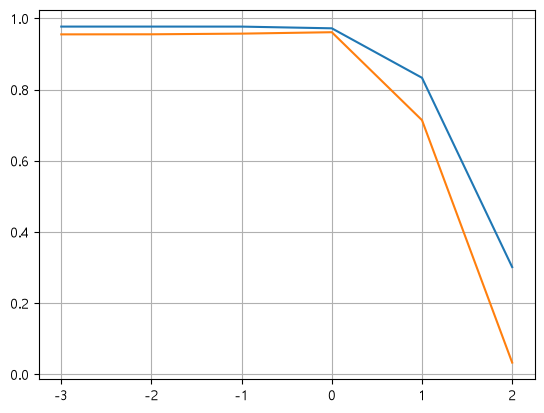

In [604]:
no_list=[1,2,3,4,5,6]
plt.plot(np.log10(alpha_list),train_score)
plt.plot(np.log10(alpha_list),test_score)

plt.grid()
plt.show()

In [605]:
ridge =Ridge(alpha=1)
ridge.fit(train_scaled,train_label)
#모델 평가
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print(score)
print(score2)

0.9721988323063082
0.9612273725160108


In [606]:
lr= LinearRegression()
lr.fit(train_poly,train_label)
score= lr.score(train_poly,train_label)
score2 =lr.score(test_poly,test_label)
print(score)
print(score2)

0.9770255436151456
0.9551480880200325


In [607]:
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values
label

array([ 10,   8,  14,  26,  22,  30,  42,  48,  38,  58,  60,  72,  62,
        68,  72,  58,  76,  86,  90, 100])

In [608]:
# 2. 훈련데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = train_test_split(data, label, random_state=42, test_size=0.2)

In [609]:
# 3. 다항 특성 자동 생성
poly = PolynomialFeatures(degree=5, include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

In [610]:
# print(poly.get_feature_names_out())

In [611]:
# 4. 표준화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [612]:
# 5. 릿지 회귀 - 규제 강도 탐색
train_score = []
test_score = []
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled, train_label)
    train_score.append(ridge.score(train_scaled, train_label))
    test_score.append(ridge.score(test_scaled, test_label))

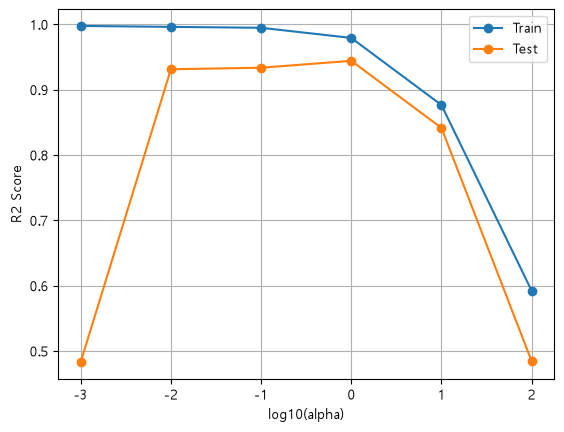

In [613]:
# 6. alpha별 성능 그래프
plt.plot(np.log10(alpha_list), train_score, marker='o')
plt.plot(np.log10(alpha_list), test_score, marker='o')
plt.xlabel('log10(alpha)')
plt.ylabel('R2 Score')
plt.legend(['Train', 'Test'])
plt.grid()
plt.show()

In [614]:
# 데이터 예측 및 오차 확인
predict = ridge.predict(test_scaled)
print("예측:",predict)

#정확도
print('train정확도:',score)
print('test정확도:',score2)

예측: [41.00602974 72.15745739 67.22293935 39.80715572]
train정확도: 0.9770255436151456
test정확도: 0.9551480880200325
